# The Growth of AI Models: Analysis of Epoch AI's Models Database
**Author:** *Lujain Al Ibrahim* · **Course:** Final Project – Unit 3

## 1. Introduction
**Dataset:** Data on AI Models, Epoch AI
**Source:** https://epoch.ai/data/ai-models

The dataset was obtained from Epoch AI and contains information on more than 3,600 AI models, covering the period from 1950 to 2026. Each row represents an individual AI model and records details such as its name, publication date, developing organisation, number of parameters, training compute, and training dataset size.

 I chose this dataset because it provides an opportunity to explore how AI models have evolved over time and investigate trends in model size, computational requirements, and the organisations driving AI development.

## 2. Problem Definition
The aim is to identify trends in AI development by exploring four main questions:
1. How has AI model size changed over time?
2. Which organisations develop the most AI models?
3. How have training compute requirements changed over time?
4. Can training compute be predicted using model size and release year?

## 3. Data Loading & Structure

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

In [6]:
import zipfile
with zipfile.ZipFile("/content/ai_models.zip") as z:
    df = pd.read_csv(z.open("all_ai_models.csv"))

### 3.1 First 5 rows

In [7]:
df.head()

,Model,Domain,Task,Organization,Authors,Publication date,Reference,Link,Citations,Notability criteria,...,Utilization notes,Numerical format,Frontier model,Training power draw (W),Training compute estimation method,Hugging Face developer id,Post-training compute (FLOP),Post-training compute notes,Hardware utilization (HFU),Open model weights?
0,DeepSeek V4.1 Flash 1017,"Language,Multimodal,Vision","Language modeling/generation,Question answering",DeepSeek,NaN,2026-10-17,DeepSeek-V4.1-Flash-1017: Wish-Driven Programm...,https://api-docs.deepseek.com/news/news261017,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Yes
1,Muse Spark Open,"Language,Multimodal,Vision,Audio,Video","Language modeling/generation,Question answering",Meta AI,NaN,2026-10-15,NaN,https://research.meta.ai/blog/muse-spark-open\...,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Yes
2,Gemini 4 Argon,"Language,Multimodal,Vision","Language modeling/generation,Question answering",Google DeepMind,NaN,2026-09-30,Gemini 4 Argon: our next era of frontier intel...,https://blog.google/innovation-and-ai/models-a...,NaN,Discretionary,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,GPT-6.1 Sol,"Multimodal,Language,Vision",Language modeling/generation,OpenAI,NaN,2026-09-29,Near-Astra intelligence for a fifth of the price,https://openai.com/index/introducing-gpt-6-1-sol/,NaN,Discretionary,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No
4,Claude Sonnet 5.5,"Language,Multimodal,Vision","Question answering,Language modeling/generation",Anthropic,NaN,2026-09-28,Claude Sonnet 5.5,https://www.anthropic.com/claude-sonnet-5-5,NaN,Discretionary,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No


### 3.2 Shape

In [8]:
df.shape

(3628, 57)

There are 3628 rows (models) , and 57 columns (features)

### 3.3 Data types

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3628 entries, 0 to 3627
Data columns (total 57 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Model                               3628 non-null   object 
 1   Domain                              3555 non-null   object 
 2   Task                                3525 non-null   object 
 3   Organization                        3553 non-null   object 
 4   Authors                             2696 non-null   object 
 5   Publication date                    3616 non-null   object 
 6   Reference                           3460 non-null   object 
 7   Link                                3589 non-null   object 
 8   Citations                           1484 non-null   float64
 9   Notability criteria                 1104 non-null   object 
 10  Notability criteria notes           862 non-null    object 
 11  Parameters                          2344 no

The `Publication date` column is stored as text (`object`) and must be converted to a datetime format to analyse trends over time.

### 3.4 Duplicates

In [10]:
df.duplicated().sum()

np.int64(0)

### 3.5 Summary statistics

In [11]:
df.describe()

,Citations,Parameters,Training compute (FLOP),Training time (hours),Epochs,Finetune compute (FLOP),Hardware quantity,Hardware utilization (MFU),Batch size,Training compute lower bound,Training compute upper bound,Training chip-hours,Training compute cost (2023 USD),Training power draw (W),Post-training compute (FLOP),Hardware utilization (HFU)
count,1484.000000,2.344000e+03,1.410000e+03,556.000000,809.000000,2.600000e+02,853.000000,61.000000,2.510000e+02,2.600000e+01,4.200000e+01,2.150000e+02,2.250000e+02,7.750000e+02,3.000000e+00,25.000000
mean,4573.545822,1.880224e+11,2.375122e+24,483.642773,560.602410,8.109851e+22,1189.824150,0.371536,5.640821e+06,9.904003e+24,5.574413e+25,1.681981e+06,6.159458e+06,1.104328e+06,3.930251e+22,0.490876
std,15773.735499,4.159629e+12,3.169419e+25,918.200926,7186.802768,3.589723e+23,8791.070877,0.111028,1.622830e+07,4.105138e+25,1.777239e+26,1.060022e+07,3.860450e+07,9.664931e+06,4.787229e+22,0.148841
min,0.000000,1.000000e+01,4.000000e+01,0.100000,0.000000,0.000000e+00,1.000000,0.171000,1.000000e+00,5.423000e+00,1.350000e+18,1.000000e+00,3.904585e+00,7.582593e+01,5.033165e+21,0.235900
25%,56.000000,1.076175e+08,1.234371e+19,39.250000,1.670000,2.135808e+19,5.000000,0.299252,1.450000e+04,3.577000e+19,5.000010e+24,2.109500e+03,1.926899e+03,4.190251e+03,1.195377e+22,0.400000
50%,493.000000,2.920000e+09,4.228942e+21,148.600000,15.000000,9.144885e+20,32.000000,0.364900,1.048576e+06,1.476000e+23,8.905000e+24,2.070000e+04,2.937447e+04,2.837469e+04,1.887437e+22,0.493500
75%,2718.000000,1.480000e+10,1.600000e+23,504.000000,100.000000,1.370700e+22,256.000000,0.462000,4.000000e+06,1.825000e+24,2.990000e+25,2.676480e+05,2.391887e+05,2.039986e+05,5.643718e+22,0.577200
max,228517.000000,1.739000e+14,9.400000e+26,9022.800000,191400.000000,2.782560e+24,200000.000000,0.560000,1.280000e+08,2.100000e+26,1.130000e+27,1.320000e+08,3.878427e+08,2.326688e+08,9.400000e+22,0.927000


The number of parameters ranges from 10 to \\(1.7 \times 10^{14}\\), so a logarithmic scale is needed to visualise the wide range clearly.

### 3.6 Missing values

In [12]:
df.isnull().sum().sort_values(ascending=False)

,0
Post-training compute notes,3625
Post-training compute (FLOP),3625
Archived links,3604
Hardware utilization (HFU),3603
Training compute lower bound,3602
Training compute upper bound,3586
Training cloud compute vendor,3574
Hardware utilization (MFU),3567
Training data center,3560
Foundation model,3550


The columns fall into three groups: nearly empty fields, key numerical variables with missing values, and categorical fields that are mostly complete.

## 4. Data Cleaning

### 4.1 Select relevant columns
Notes, abstracts, and authors were removed because they are not essential to the main analysis, while near-empty columns were excluded to reduce missing data and keep the dataset relevant.

In [13]:
cols = [
    "Model", "Domain", "Organization", "Country (of organization)",
    "Organization categorization", "Publication date", "Parameters",
    "Training compute (FLOP)", "Training dataset size (total)",
    "Training hardware", "Model accessibility", "Open model weights?",
    "Confidence", "Citations", "Frontier model",
]
df_clean = df[cols].copy()
df_clean.shape

(3628, 15)

### 4.2 Rename columns
Shorter names without spaces are easier to work with.

In [14]:
df_clean = df_clean.rename(columns={
    "Model": "model", "Domain": "domain", "Organization": "organization",
    "Country (of organization)": "country",
    "Organization categorization": "org_type",
    "Publication date": "date", "Parameters": "parameters",
    "Training compute (FLOP)": "compute_flop",
    "Training dataset size (total)": "dataset_size",
    "Training hardware": "hardware", "Model accessibility": "accessibility",
    "Open model weights?": "open_weights", "Confidence": "confidence",
    "Citations": "citations", "Frontier model": "frontier",
})

### 4.3 Convert data types

In [15]:
df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")
df_clean["year"] = df_clean["date"].dt.year

df_clean["dataset_size"] = pd.to_numeric(df_clean["dataset_size"], errors="coerce")

df_clean["frontier"] = df_clean["frontier"].fillna(False).astype(bool)

/tmp/ipykernel_710/3763306024.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_clean["frontier"] = df_clean["frontier"].fillna(False).astype(bool)


### 4.4 Handle missing values
- Rows with no publication date are dropped (12 rows), since they cannot be placed on a timeline.
- Categorical columns are filled with `"Unknown"`, so missing becomes its own group.
- Numeric columns are left as NaN. Filling them with the median would turn the largest, undisclosed models into average-sized ones.

In [16]:
# 1. rows with no date can't be placed on a timeline, so drop (only 12)
df_clean = df_clean.dropna(subset=["date"])

# 2. categories: "Unknown" becomes its own group
cat_cols = ["domain", "organization", "country", "org_type",
            "hardware", "accessibility", "open_weights", "confidence"]
df_clean[cat_cols] = df_clean[cat_cols].fillna("Unknown")

# 3. numbers: leave them as NaN
df_clean.isnull().sum()

,0
model,0
domain,0
organization,0
country,0
org_type,0
date,0
parameters,1272
compute_flop,2206
dataset_size,2205
hardware,0


In [17]:
df_clean["year"] = df_clean["year"].astype(int)

### 4.5 Log-transformed columns
The numeric columns span many orders of magnitude, so log10 versions are created for plotting and modelling. 4 models have a dataset size of 0; the log of zero is undefined, so these are treated as missing.

In [18]:
(df_clean[["parameters", "compute_flop", "dataset_size"]] == 0).sum()

,0
parameters,0
compute_flop,0
dataset_size,4


In [19]:
for c in ["parameters", "compute_flop", "dataset_size"]:
    df_clean[f"log_{c}"] = np.log10(df_clean[c].where(df_clean[c] > 0))

### 4.6 Group categories
The `domain` and `org_type` columns list the same combinations in different orders (e.g. "Multimodal,Language,Vision" and "Language,Vision,Multimodal", or "Academia,Academia"). Each model is given one main domain and one organization group.

In [20]:
def main_domain(d):
    if d == "Unknown":
        return "Unknown"
    parts = d.split(",")
    if len(parts) > 1:
        return "Multimodal"
    return parts[0]

df_clean["main_domain"] = df_clean["domain"].apply(main_domain)
df_clean["main_domain"].value_counts().head(10)

,count
main_domain,
Language,1611
Multimodal,622
Biology,376
Vision,321
Image generation,167
Speech,131
Video,61
Unknown,61
Games,58


In [21]:
top5 = df_clean["main_domain"].value_counts().head(5).index
df_clean["domain_group"] = df_clean["main_domain"].where(
    df_clean["main_domain"].isin(top5), "Other")
df_clean["domain_group"].value_counts()

,count
domain_group,
Language,1611
Multimodal,622
Other,519
Biology,376
Vision,321
Image generation,167


In [22]:
def org_group(s):
    parts = set(s.split(","))   # set() removes repeats: {"Academia","Academia"}
    if parts == {"Unknown"}:
        return "Unknown"
    if len(parts) > 1:
        return "Collaboration"
    return parts.pop()

df_clean["org_group"] = df_clean["org_type"].apply(org_group)
df_clean["org_group"].value_counts()

,count
org_group,
Industry,1958
Academia,818
Collaboration,699
Unknown,88
Research collective,29
Government,24


### 4.7 Save the cleaned dataset

In [23]:
df_clean.to_csv("clean_data.csv", index=False)
print(df_clean.shape)
df_clean.isnull().sum()

(3616, 22)


,0
model,0
domain,0
organization,0
country,0
org_type,0
date,0
parameters,1272
compute_flop,2206
dataset_size,2205
hardware,0


## 5. Exploratory Data Analysis

### 5.1 Univariate analysis

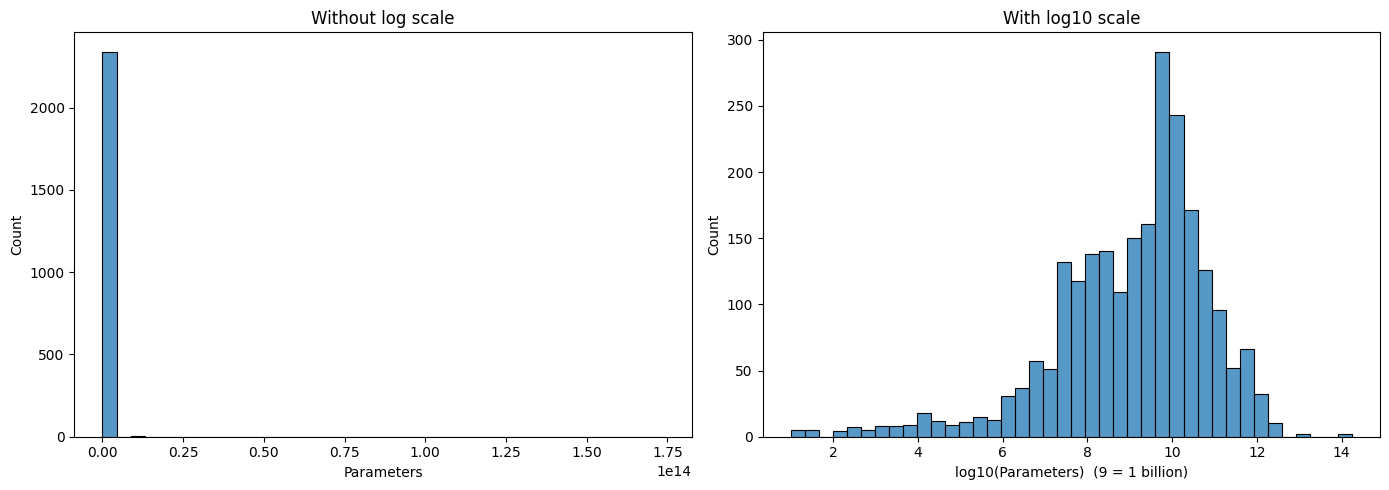

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean["parameters"].dropna(), bins=40, ax=axes[0])
axes[0].set_title("Without log scale")
axes[0].set_xlabel("Parameters")

sns.histplot(df_clean["log_parameters"].dropna(), bins=40, ax=axes[1])
axes[1].set_title("With log10 scale")
axes[1].set_xlabel("log10(Parameters)  (9 = 1 billion)")

plt.tight_layout()
plt.show()

**Figure 1: Model size with and without a log scale.**
On the raw scale (left), 99.8% of the 2,344 models with a known parameter count fall into the first bar. A few extreme models stretch the x-axis to 10¹⁴: BaGuaLu (174 trillion), Persia (100 trillion) and DLRM-12T (12 trillion). Because of them, the chart tells us almost nothing about a typical model.

On the log10 scale (right), the shape becomes clear. The median model has about 2.9 billion parameters (log ≈ 9.5). The middle half of models fall between about 100 million and 15 billion (log 8 to 10.2), and 83% of models fall between 1 million and 100 billion parameters.

Takeaway: model size spans about 13 orders of magnitude, so all further size and compute charts use a log scale.

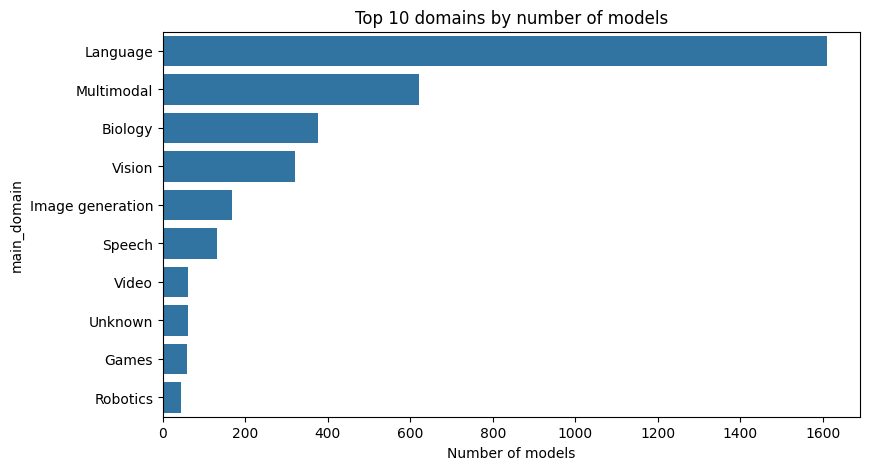

In [25]:
plt.figure(figsize=(9, 5))
top_domains = df_clean["main_domain"].value_counts().head(10).index
sns.countplot(data=df_clean[df_clean["main_domain"].isin(top_domains)],
              y="main_domain", order=top_domains)
plt.title("Top 10 domains by number of models")
plt.xlabel("Number of models")
plt.show()

**Figure 2: Top 10 domains by number of models.**

Language is by far the largest domain, with 1,611 models about 45% . That’s roughly 4 times as many as the next domain, Biology (376), followed by Vision (321). Image generation (167) and Speech (131) are much smaller. Games has only 58 models, even though game-playing systems like AlphaGo were some of the most famous AI milestones.

The chart also revealed a data quality issue. “Multimodal,Language,Vision” (85) and “Language,Vision,Multimodal” (54) are the same combination written in a different order, so they were counted separately. I fixed this by creating a main_domain column that groups any model with several domains as “Multimodal”.

Takeaway: the AI field in this dataset is dominated by language models, most likely driven by the rise of large language models like ChatGPT.

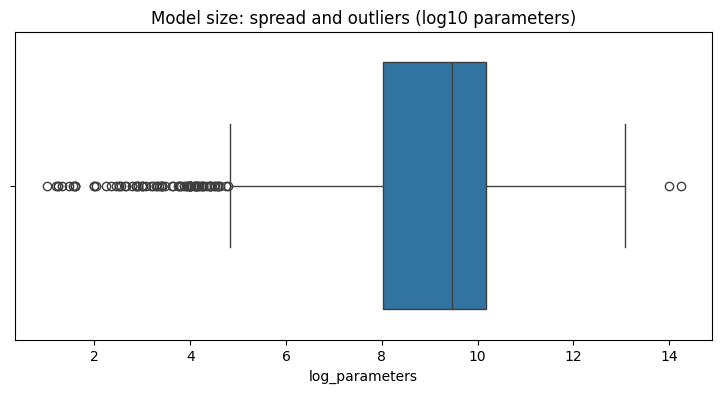

In [26]:
plt.figure(figsize=(9, 4))
sns.boxplot(x=df_clean["log_parameters"])
plt.title("Model size: spread and outliers (log10 parameters)")
plt.show()

**Figure 3: Spread and outliers of model size.**

The middle 50% of models have between about 100 million and 15 billion parameters (log 8 to 10.2), and the median model has about 3 billion.

The outliers are lopsided. There are 83 unusually small models on the left (under about 100,000 parameters) but only 2 unusually large ones on the right (BaGuaLu and Persia, both above 100 trillion). The small outliers are mostly old models: their median publication year is 1993, and about 80% were published before 2010.

Takeaway: these outliers aren’t errors, so I kept them. The small ones show what AI looked like decades ago, and the two giants are special-purpose systems. This suggests model size depends heavily on when a model was built, which the next chart explores.

### 5.2 Bivariate & multivariate analysis

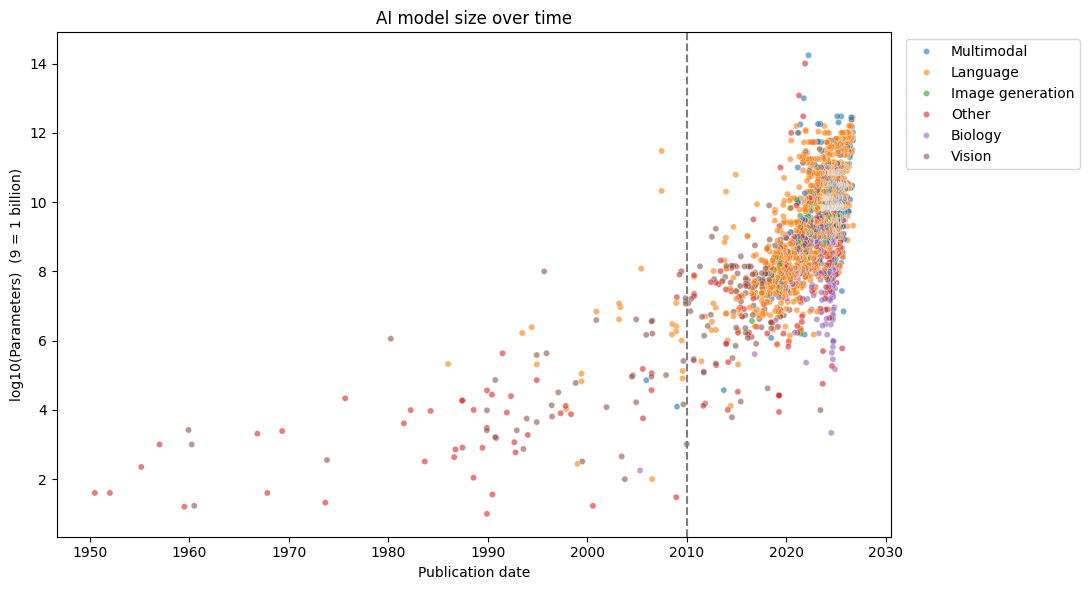

In [27]:
plt.figure(figsize=(11, 6))
sns.scatterplot(data=df_clean, x="date", y="log_parameters",
                hue="domain_group", alpha=0.6, s=20)
plt.axvline(pd.Timestamp("2010-01-01"), color="grey", linestyle="--")
plt.ylabel("log10(Parameters)  (9 = 1 billion)")
plt.xlabel("Publication date")
plt.title("AI model size over time")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Figure 4: AI model size over time.**

The chart shows two very different eras.

Before 2010, models were small and grew slowly, and size grew only about 1.2× per year, doubling every 4 years.

After 2010, which is the start of the deep learning era, growth sped up sharply: about 2× per year, doubling every 12 months. Since 2020, the median model has about 7 billion parameters.

The field also exploded in volume. 84% of all models (3,042) in the dataset were published from 2018 onwards, and the dense cloud on the right is dominated by Language models.

Interesting outliers: two language models from 2007 (SB-LM and KN-LM) sit far above everything around them. These weren’t neural networks. They were simple word-count models (n-gram models) built from huge amounts of web text. They’re huge, but simple, which again shows that parameter count alone doesn’t measure how capable a model is.

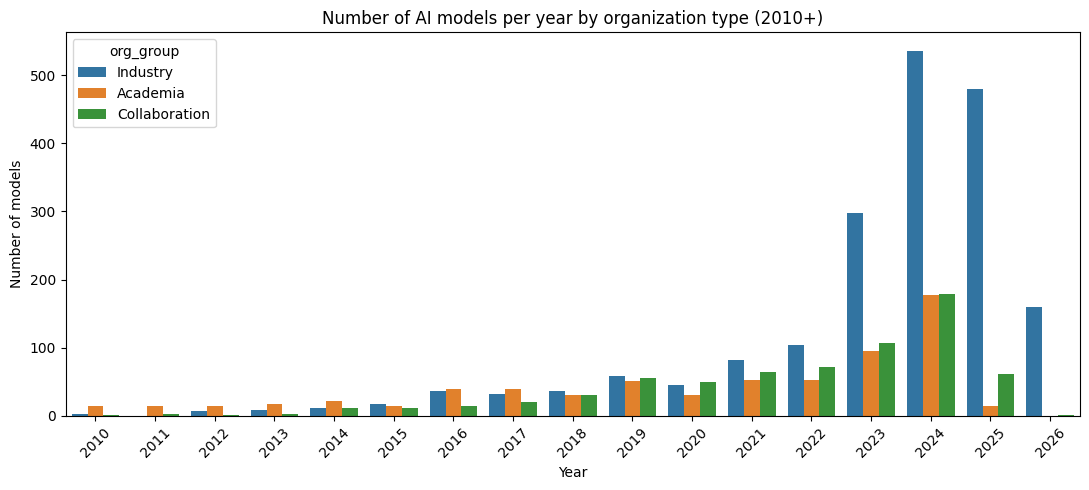

In [28]:
recent = df_clean[df_clean["year"] >= 2010]
groups = ["Industry", "Academia", "Collaboration"]

plt.figure(figsize=(11, 5))
sns.countplot(data=recent[recent["org_group"].isin(groups)],
              x="year", hue="org_group", hue_order=groups)
plt.title("Number of AI models per year by organization type (2010+)")
plt.xticks(rotation=45)
plt.xlabel("Year")
plt.ylabel("Number of models")
plt.tight_layout()
plt.show()

**Figure 5: AI models per year by organization type (2010+).**

In the early 2010s, universities led. In 2012, academia published 14 models compared with industry’s 7.

From 2015 to 2017 the two were even. From 2018 onwards industry stayed ahead every year, and the gap grew dramatically after 2022, when ChatGPT launched. In 2024, industry released 536 models, compared with 177 from academia and 179 from collaborations, so industry produced about 3 times as many as academia.

Why the shift? Training large models now needs enormous amounts of compute and money, which companies have and most universities don’t. This connects to the size-over-time chart: as models grew, building them moved to industry.

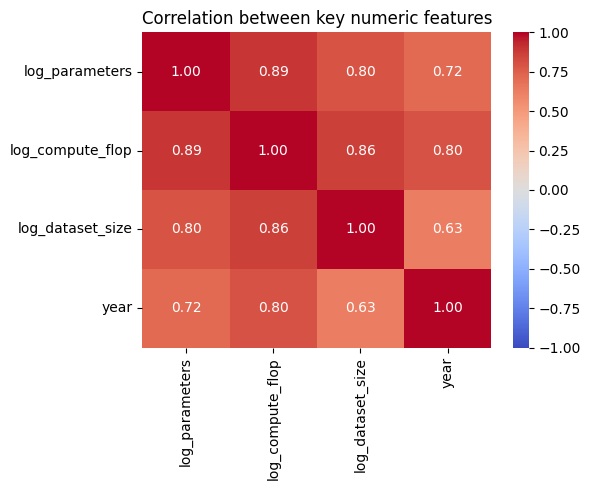

In [29]:
num_cols = ["log_parameters", "log_compute_flop", "log_dataset_size", "year"]

plt.figure(figsize=(6, 5))
sns.heatmap(df_clean[num_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between key numeric features")
plt.tight_layout()
plt.show()

**Figure 6: Correlation between key numeric features.**

All four features are strongly and positively correlated: when one goes up, the others tend to go up too. Training compute is most closely linked to model size (0.89) and dataset size (0.86). This makes sense, because training a bigger model on more data takes more computation. Compute is also strongly linked to year (0.80), which confirms the growth we saw in the scatter plot: newer models are trained with far more compute.

The weakest link is between dataset size and year (0.63). Datasets have grown over time, but less consistently than model size.


## 6. Prediction Model
The question: can we predict how much compute a model needed for training from its size and release year? This is useful in real life, because many labs hide their compute numbers but do reveal model size.

A linear regression model is used. Because we’re working on log scales, that “straight line” actually captures the huge exponential growth.

### 6.1 Prepare the data

In [30]:
features = ["log_parameters", "year"]
target = "log_compute_flop"

model_df = df_clean.dropna(subset=features + [target])
print("Models with complete data:", len(model_df))

X = model_df[features]
y = model_df[target]

Models with complete data: 1253


### 6.2 Train/test split
80% of the models are used for training and 20% are for testing.

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

### 6.3 Train and evaluate

In [32]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("R²: ", round(r2_score(y_test, y_pred), 3))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("Coefficients:", dict(zip(features, model.coef_.round(3))))

R²:  0.851
MAE: 1.058
Coefficients: {'log_parameters': np.float64(1.184), 'year': np.float64(0.154)}


predicting training compute. A linear regression using log parameters and publication year was trained on 80% of the 1,253 models with complete data, and tested on the remaining 20%. It achieved R² = 0.85, so it explains 85% of the variation in compute. The mean absolute error was 1.06 on the log scale, meaning typical predictions are within about a factor of 10 of the true value.

### 6.4 Predicted vs actual

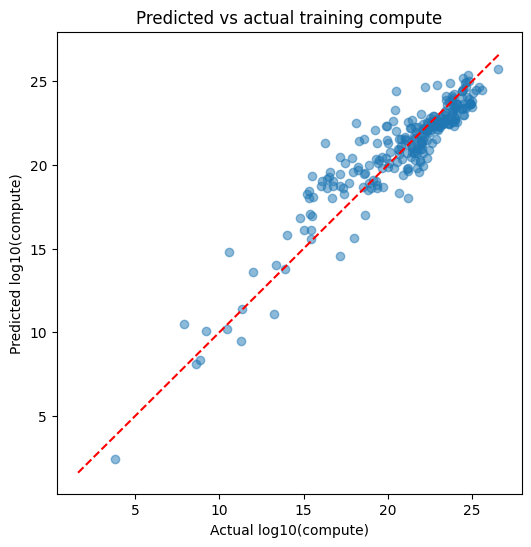

In [33]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual log10(compute)")
plt.ylabel("Predicted log10(compute)")
plt.title("Predicted vs actual training compute")
plt.show()

**Figure 7: Predicted vs actual training compute.**

Most points sit close to the red line, which matches the R² of 0.85. Two patterns stand out:

- Between about 15 and 19 on the x-axis, most points sit above the line: the model overestimates compute for these mid-sized, mostly older models.
- At the top right (above 25), points sit slightly below the line: the model underestimates the very largest models, which are trained with more compute than size and year alone would suggest.

### 6.5 Comparing feature sets

In [34]:
def train_and_score(features):
    data = df_clean.dropna(subset=features + [target])
    X_train, X_test, y_train, y_test = train_test_split(
        data[features], data[target], test_size=0.2, random_state=42)
    m = LinearRegression().fit(X_train, y_train)
    pred = m.predict(X_test)
    return {
        "features": ", ".join(features),
        "n_models": len(data),
        "R2": round(r2_score(y_test, pred), 3),
        "MAE": round(mean_absolute_error(y_test, pred), 3),
    }

results = pd.DataFrame([
    train_and_score(["log_parameters", "year"]),
    train_and_score(["log_parameters", "log_dataset_size", "year"]),
])
results

,features,n_models,R2,MAE
0,"log_parameters, year",1253,0.851,1.058
1,"log_parameters, log_dataset_size, year",861,0.930,0.831


Adding dataset size improved accuracy (R² from 0.85 to 0.93, MAE from 1.06 to 0.83), confirming that compute depends on both model size and the amount of training data. However, it reduced the usable data from 1,253 to 861 models, and dataset size is often unreported in practice. I chose the simpler model (parameters + year) for the dashboard, because it can make predictions for more models, while the three-feature model is reported as the more accurate option when dataset size is known.

## 7. Insights Summary
Patterns: AI development accelerated after 2010, with significant growth in model size and training compute.



Relationships: Larger models generally require more training compute, and both tend to increase over time.



Outliers: Early models, such as the 2007 n-gram models, were much smaller, while models such as BaGuaLu and Persia stand out in the dataset.



Key takeaways: AI models have become increasingly complex and resource-intensive, reflecting rapid advances in AI technology.

## 8. Limitations & Future Work
Missing data: Many models lack parameter counts or training compute information, particularly newer models.



Incomplete years: Data for 2025–2026 may be incomplete, as models are added over time.



Prediction limitations: The prediction model uses only around one-third of models with complete data, which may introduce bias.



Future work: Include more recent data, improve missing-value handling, and explore additional features to improve prediction accuracy.

## References
- Epoch AI, *Data on AI Models*, https://epoch.ai/data/ai-models

In [35]:
from google.colab import files
files.download("clean_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>